# Credit Card Fraud Detection Using Machine Learning

### Project Overview

## Part A – Importing and Understanding the Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("creditcard.csv")

In [3]:
# Display the first 10 rows
df.head(10)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
5,2.0,-0.425966,0.960523,1.141109,-0.168252,0.420987,-0.029728,0.476201,0.260314,-0.568671,...,-0.208254,-0.559825,-0.026398,-0.371427,-0.232794,0.105915,0.253844,0.081080,3.67,0
6,4.0,1.229658,0.141004,0.045371,1.202613,0.191881,0.272708,-0.005159,0.081213,0.464960,...,-0.167716,-0.270710,-0.154104,-0.780055,0.750137,-0.257237,0.034507,0.005168,4.99,0
7,7.0,-0.644269,1.417964,1.074380,-0.492199,0.948934,0.428118,1.120631,-3.807864,0.615375,...,1.943465,-1.015455,0.057504,-0.649709,-0.415267,-0.051634,-1.206921,-1.085339,40.80,0
8,7.0,-0.894286,0.286157,-0.113192,-0.271526,2.669599,3.721818,0.370145,0.851084,-0.392048,...,-0.073425,-0.268092,-0.204233,1.011592,0.373205,-0.384157,0.011747,0.142404,93.20,0
9,9.0,-0.338262,1.119593,1.044367,-0.222187,0.499361,-0.246761,0.651583,0.069539,-0.736727,...,-0.246914,-0.633753,-0.120794,-0.385050,-0.069733,0.094199,0.246219,0.083076,3.68,0


In [4]:
# Display the number of rows and columns
df.shape

(284807, 31)

In [5]:
# Display all column names
print(df.columns.tolist())

['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']


In [6]:
target_column = "Class"
print("Target column:", target_column)

Target column: Class


In [7]:
# Display dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [8]:
# Generate descriptive statistics for all numerical columns
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.168375e-15,3.416908e-16,-1.379537e-15,2.074095e-15,9.604066e-16,1.487313e-15,-5.556467e-16,1.213481e-16,-2.406331e-15,...,1.654067e-16,-3.568593e-16,2.578648e-16,4.473266e-15,5.340915e-16,1.683437e-15,-3.660091e-16,-1.227390e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [9]:
# Calculate descriptive statistics for Amount
print("Mean:", df['Amount'].mean())
print("Median:", df['Amount'].median())
print("Minimum:", df['Amount'].min())
print("Maximum:", df['Amount'].max())
print("Standard Deviation:", df['Amount'].std())

Mean: 88.34961925093133
Median: 22.0
Minimum: 0.0
Maximum: 25691.16
Standard Deviation: 250.1201092402221


In [10]:
# Count transactions in each Class
class_counts = df['Class'].value_counts()

print("Transaction counts:")
print(class_counts)

# Calculate percentages
class_percentages = df['Class'].value_counts(normalize=True) * 100

print("\nTransaction percentages:")
print(class_percentages)

Transaction counts:
Class
0    284315
1       492
Name: count, dtype: int64

Transaction percentages:
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


## Part B – Data Cleaning

In [11]:
# Check missing values in each column
print(df.isnull().sum())

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64


In [12]:
# Count duplicate rows
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 1081


In [13]:
# Remove duplicate records
df = df.drop_duplicates()

# Verify the new shape
print("New shape of DataFrame:", df.shape)

New shape of DataFrame: (283726, 31)


In [14]:
# Calculate the first and third quartiles
Q1 = df['Amount'].quantile(0.25)
Q3 = df['Amount'].quantile(0.75)

# Calculate the Interquartile Range
IQR = Q3 - Q1

# Determine the lower and upper bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify outliers
outliers = df[(df['Amount'] < lower_bound) |
              (df['Amount'] > upper_bound)]

# Display the results
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Number of outliers:", len(outliers))

Q1: 5.6
Q3: 77.51
IQR: 71.91000000000001
Lower bound: -102.26500000000001
Upper bound: 185.375
Number of outliers: 31685


In [15]:
# Create the Transaction_Type column
df['Transaction_Type'] = df['Class'].map({0: 'Normal',1: 'Fraud'})

# Display the first 10 rows
df[['Class', 'Transaction_Type']].head(10)

,Class,Transaction_Type
0,0,Normal
1,0,Normal
2,0,Normal
3,0,Normal
4,0,Normal
5,0,Normal
6,0,Normal
7,0,Normal
8,0,Normal
9,0,Normal


In [16]:
print(df['Transaction_Type'].value_counts())

Transaction_Type
Normal    283253
Fraud        473
Name: count, dtype: int64


## Part C — Data Analysis and Visualization

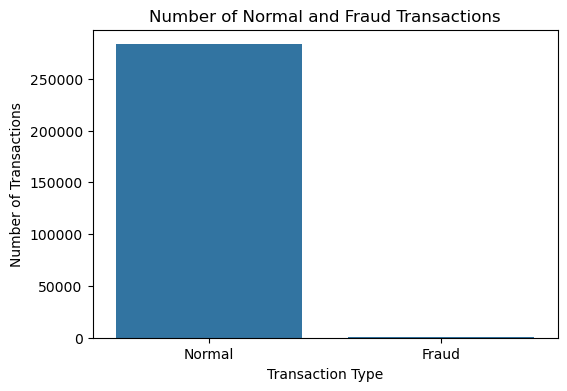

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count transactions by type
transaction_counts = df['Transaction_Type'].value_counts().reindex(['Normal', 'Fraud'])

# Create bar chart
plt.figure(figsize=(6, 4))
sns.barplot(x=transaction_counts.index, y=transaction_counts.values)

plt.title('Number of Normal and Fraud Transactions')
plt.xlabel('Transaction Type')
plt.ylabel('Number of Transactions')
plt.show()

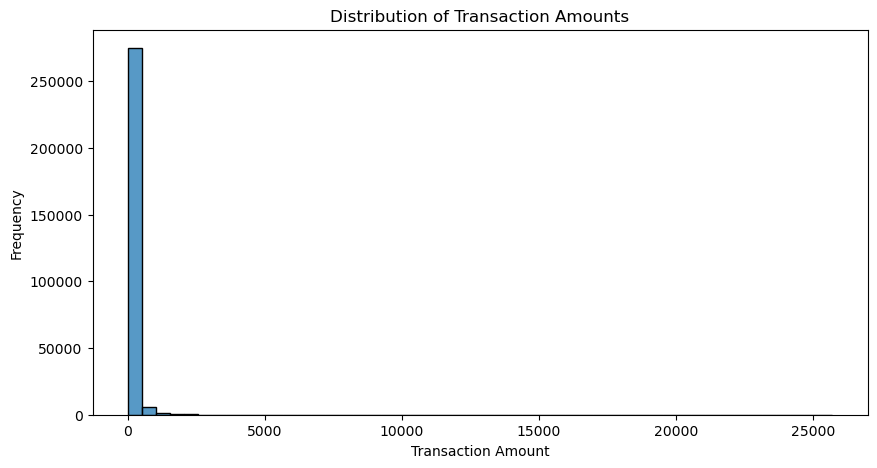

In [18]:

# Create a histogram of transaction Amount
plt.figure(figsize=(10, 5))

sns.histplot(data=df, x='Amount', bins=50)

plt.title('Distribution of Transaction Amounts')
plt.xlabel('Transaction Amount')
plt.ylabel('Frequency')

plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

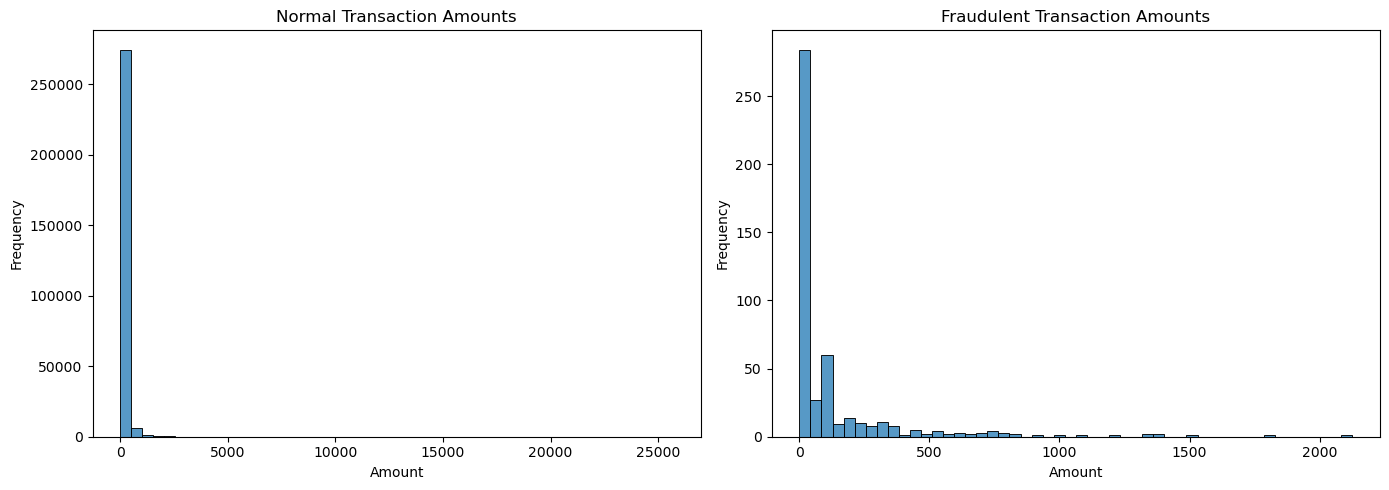

In [19]:

# Create separate histograms
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Normal transactions
sns.histplot(data=df[df['Class'] == 0],x='Amount',bins=50,ax=axes[0])
axes[0].set_title('Normal Transaction Amounts')
axes[0].set_xlabel('Amount')
axes[0].set_ylabel('Frequency')

# Fraudulent transactions
sns.histplot(data=df[df['Class'] == 1],x='Amount',bins=50,ax=axes[1])
axes[1].set_title('Fraudulent Transaction Amounts')
axes[1].set_xlabel('Amount')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show

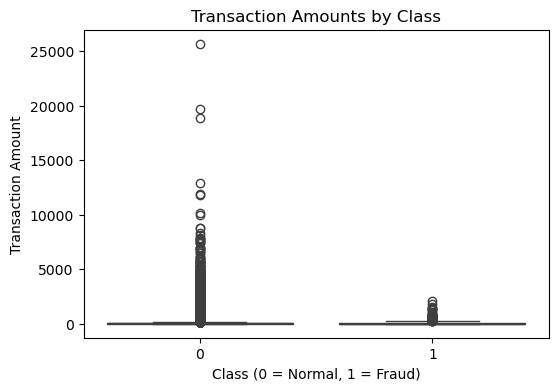

In [20]:

# Create a box plot grouped by Class
plt.figure(figsize=(6, 4))

sns.boxplot(data=df, x='Class', y='Amount')

plt.title('Transaction Amounts by Class')
plt.xlabel('Class (0 = Normal, 1 = Fraud)')
plt.ylabel('Transaction Amount')

plt.show()

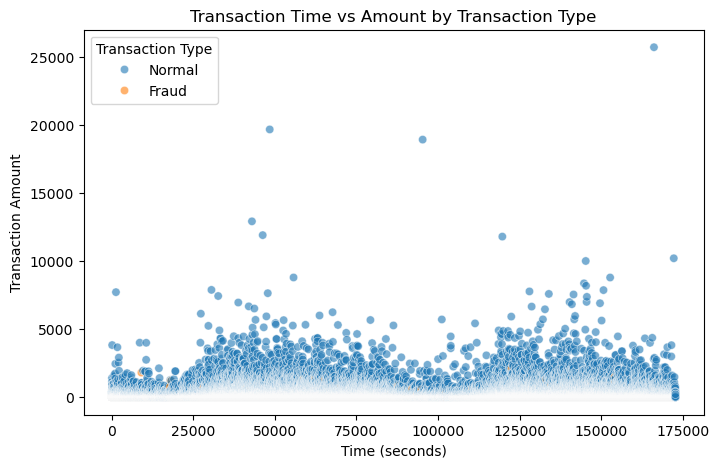

In [21]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df,x='Time',y='Amount',hue='Transaction_Type',alpha=0.6)

plt.title('Transaction Time vs Amount by Transaction Type')
plt.xlabel('Time (seconds)')
plt.ylabel('Transaction Amount')
plt.legend(title='Transaction Type')
plt.show()

          Amount     Class        V1        V2        V3        V4       V10  \
Amount  1.000000  0.005777 -0.230105 -0.533428 -0.212410  0.099514 -0.102255   
Class   0.005777  1.000000 -0.094486  0.084624 -0.182322  0.129326 -0.206971   
V1     -0.230105 -0.094486  1.000000  0.006875 -0.008112  0.002257  0.000815   
V2     -0.533428  0.084624  0.006875  1.000000  0.005278 -0.001495  0.000620   
V3     -0.212410 -0.182322 -0.008112  0.005278  1.000000  0.002829 -0.009632   
V4      0.099514  0.129326  0.002257 -0.001495  0.002829  1.000000  0.002753   
V10    -0.102255 -0.206971  0.000815  0.000620 -0.009632  0.002753  1.000000   
V11    -0.000015  0.149067  0.001028 -0.000633  0.002339 -0.001223  0.000844   
V12    -0.009254 -0.250711 -0.001524  0.002266 -0.005900  0.003366 -0.006942   
V14     0.034122 -0.293375 -0.002663  0.002711 -0.003027  0.002801  0.000168   
V17     0.007730 -0.313498 -0.003491  0.003244 -0.008159  0.003655 -0.007877   

             V11       V12       V14   

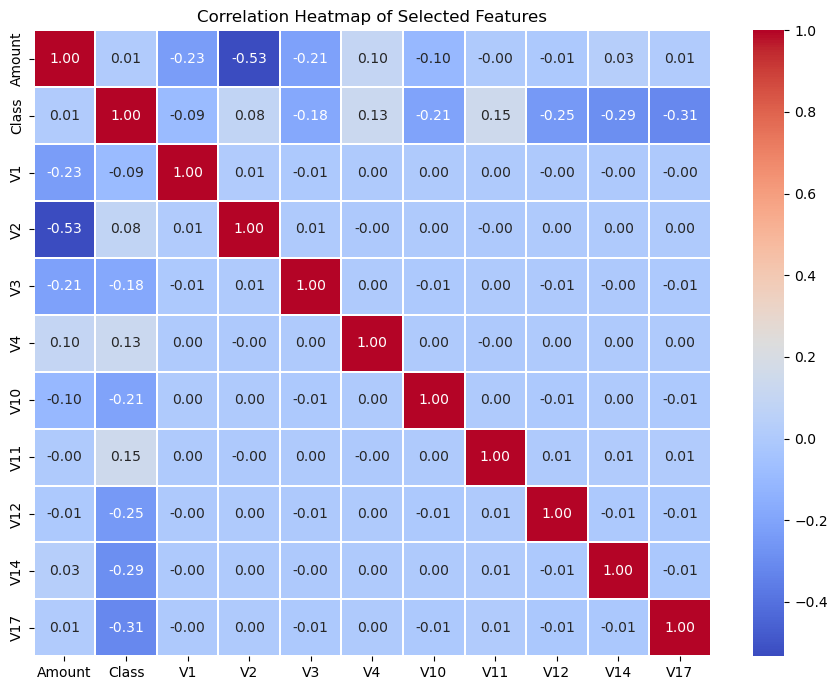

In [22]:

# Select the required columns
selected_columns = ['Amount', 'Class', 'V1', 'V2', 'V3', 'V4', 'V10', 'V11', 'V12', 'V14', 'V17']

# Calculate the correlation matrix
correlation_matrix = df[selected_columns].corr()

# Display the correlation matrix
print(correlation_matrix)

# Create the correlation heatmap
plt.figure(figsize=(9, 7))

sns.heatmap(correlation_matrix,annot=True,cmap='coolwarm',fmt='.2f',linewidths=0.3)

plt.title('Correlation Heatmap of Selected Features')
plt.tight_layout()
plt.show()

Top 5 features by absolute correlation with Class:
V17   -0.313498
V14   -0.293375
V12   -0.250711
V10   -0.206971
V16   -0.187186
Name: Class, dtype: float64


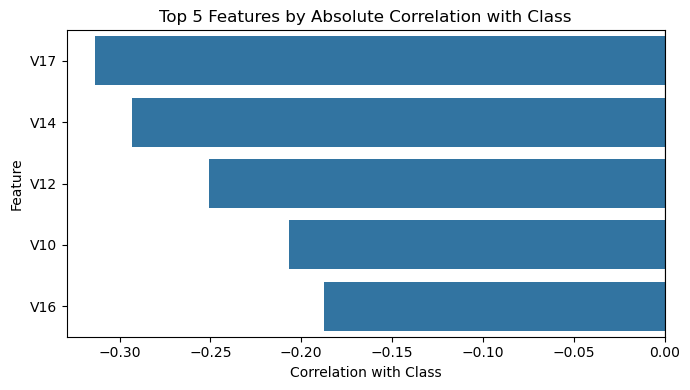

In [23]:

# Calculate correlations with Class
correlations = df.corr(numeric_only=True)['Class'].drop('Class')

# Select the five features with the strongest absolute correlations
top_5_features = correlations.abs().nlargest(5).index
top_5_correlations = correlations.loc[top_5_features]

# Display the results
print("Top 5 features by absolute correlation with Class:")
print(top_5_correlations)

# Create a bar chart
plt.figure(figsize=(7, 4))

sns.barplot(x=top_5_correlations.values,y=top_5_correlations.index)

plt.title('Top 5 Features by Absolute Correlation with Class')
plt.xlabel('Correlation with Class')
plt.ylabel('Feature')
plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

## Part D — Supervised Machine Learning

In [24]:
# Separate features (X) and target (y)
X = df.drop(columns=['Class', 'Transaction_Type'])
y = df['Class']

# Check the shapes
print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)

Features (X) shape: (283726, 30)
Target (y) shape: (283726,)


In [25]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

# Display the shapes
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (226980, 30)
X_test shape: (56746, 30)
y_train shape: (226980,)
y_test shape: (56746,)


In [26]:
from sklearn.preprocessing import StandardScaler

# Initialize the scaler
scaler = StandardScaler()

# Select columns to scale
columns_to_scale = ['Amount', 'Time']

# Fit on training data and transform it
X_train[columns_to_scale] = scaler.fit_transform(X_train[columns_to_scale])

# Transform test data using the same scaler
X_test[columns_to_scale] = scaler.transform(X_test[columns_to_scale])

# Verify the scaled values
print(X_train[columns_to_scale].head())

          Amount      Time
226238 -0.229434  1.045499
134253 -0.331197 -0.298690
186465 -0.298809  0.678397
149493 -0.289247 -0.074929
18461  -0.261985 -1.376728


### Logistic Regression

In [27]:
from sklearn.linear_model import LogisticRegression

# Initialize the Logistic Regression model
lr_model = LogisticRegression(random_state=42,max_iter=1000
)

# Train the model
lr_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [28]:
from sklearn.metrics import (confusion_matrix,accuracy_score,precision_score,recall_score,f1_score,classification_report)

# Predict the test-set labels
y_pred = lr_model.predict(X_test)

# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("\nAccuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)

# Detailed classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Confusion Matrix:
[[56641    10]
 [   39    56]]

Accuracy: 0.9991365030134283
Precision: 0.8484848484848485
Recall: 0.5894736842105263
F1-score: 0.6956521739130435

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.85      0.59      0.70        95

    accuracy                           1.00     56746
   macro avg       0.92      0.79      0.85     56746
weighted avg       1.00      1.00      1.00     56746



### Decision Tree Classifier

In [29]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (confusion_matrix,accuracy_score,precision_score,recall_score,f1_score,classification_report)

# Initialize the Decision Tree model
dt_model = DecisionTreeClassifier(random_state=42)

# Train the model
dt_model.fit(X_train, y_train)

# Predict on the test data
y_pred_dt = dt_model.predict(X_test)

# Confusion matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))

# Evaluation metrics
print("\nAccuracy:", accuracy_score(y_test, y_pred_dt))
print("Precision:", precision_score(y_test, y_pred_dt, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_dt, zero_division=0))
print("F1-score:", f1_score(y_test, y_pred_dt, zero_division=0))

# Detailed classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt, zero_division=0))

Confusion Matrix:
[[56625    26]
 [   28    67]]

Accuracy: 0.999048391076023
Precision: 0.7204301075268817
Recall: 0.7052631578947368
F1-score: 0.7127659574468085

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.72      0.71      0.71        95

    accuracy                           1.00     56746
   macro avg       0.86      0.85      0.86     56746
weighted avg       1.00      1.00      1.00     56746



### Random Forest Classifier

In [30]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

# 1. Train the Random Forest model
rf_model = RandomForestClassifier(n_estimators=100,random_state=42,n_jobs=-1)

rf_model.fit(X_train, y_train)

# 2. Make predictions
y_pred_rf = rf_model.predict(X_test)

# 3. Compare all three models
comparison = pd.DataFrame({'Model': ['Logistic Regression', 'Decision Tree', 'Random Forest'],
    'Precision': [
        precision_score(y_test, y_pred, zero_division=0),
        precision_score(y_test, y_pred_dt, zero_division=0),
        precision_score(y_test, y_pred_rf, zero_division=0)],
    'Recall': [
        recall_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred_dt, zero_division=0),
        recall_score(y_test, y_pred_rf, zero_division=0)],
    'F1-score': [
        f1_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred_dt, zero_division=0),
        f1_score(y_test, y_pred_rf, zero_division=0)]})

print(comparison.round(4))

                 Model  Precision  Recall  F1-score
0  Logistic Regression     0.8485  0.5895    0.6957
1        Decision Tree     0.7204  0.7053    0.7128
2        Random Forest     0.9718  0.7263    0.8313


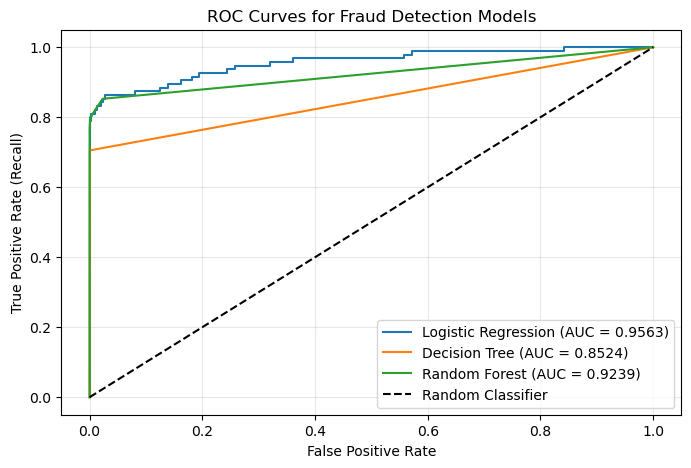

              Model  ROC-AUC
Logistic Regression 0.956345
      Random Forest 0.923944
      Decision Tree 0.852402

Best model based on ROC-AUC: Logistic Regression


In [32]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import roc_curve, roc_auc_score

# Define the trained models
models = {'Logistic Regression': lr_model,'Decision Tree': dt_model,'Random Forest': rf_model}

auc_results = {}

# Plot ROC curves
plt.figure(figsize=(8, 5))

for name, model in models.items():

    # Predict probability of Fraud (Class = 1)
    y_prob = model.predict_proba(X_test)[:, 1]

    # Calculate ROC curve and ROC-AUC
    fpr, tpr, thresholds = roc_curve(y_test, y_prob)
    auc_score = roc_auc_score(y_test, y_prob)

    auc_results[name] = auc_score

    plt.plot(
        fpr, tpr,
        label=f'{name} (AUC = {auc_score:.4f})'
    )

# Random classifier reference line
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curves for Fraud Detection Models')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()

# Display ROC-AUC comparison
auc_comparison = pd.DataFrame(
    list(auc_results.items()),
    columns=['Model', 'ROC-AUC']
).sort_values('ROC-AUC', ascending=False)

print(auc_comparison.to_string(index=False))

# Identify the best model
best_model = max(auc_results, key=auc_results.get)
print(f"\nBest model based on ROC-AUC: {best_model}")

### Handle class imbalance using class weighting

In [33]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    recall_score,
    precision_score,
    f1_score,
    classification_report
)

# Train Logistic Regression with balanced class weights
lr_balanced = LogisticRegression(
    class_weight='balanced',
    random_state=42,
    max_iter=1000
)

lr_balanced.fit(X_train, y_train)

# Predict test data
y_pred_balanced = lr_balanced.predict(X_test)

# Evaluate the balanced model
print("Balanced Logistic Regression Results")
print("Precision:", precision_score(
    y_test, y_pred_balanced, zero_division=0
))
print("Recall:", recall_score(
    y_test, y_pred_balanced, zero_division=0
))
print("F1-score:", f1_score(
    y_test, y_pred_balanced, zero_division=0
))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred_balanced, zero_division=0
))

Balanced Logistic Regression Results
Precision: 0.05623306233062331
Recall: 0.8736842105263158
F1-score: 0.10566518141311267

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56651
           1       0.06      0.87      0.11        95

    accuracy                           0.98     56746
   macro avg       0.53      0.92      0.55     56746
weighted avg       1.00      0.98      0.99     56746



### Compare fraud recall before and after balancing

In [34]:
import pandas as pd
from sklearn.metrics import recall_score, precision_score, f1_score

comparison = pd.DataFrame({
    'Model': [
        'Original Logistic Regression',
        'Balanced Logistic Regression'
    ],
    'Precision': [
        precision_score(y_test, y_pred, zero_division=0),
        precision_score(y_test, y_pred_balanced, zero_division=0)
    ],
    'Fraud Recall': [
        recall_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred_balanced, zero_division=0)
    ],
    'F1-score': [
        f1_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred_balanced, zero_division=0)
    ]
})

print(comparison.round(4))

                          Model  Precision  Fraud Recall  F1-score
0  Original Logistic Regression     0.8485        0.5895    0.6957
1  Balanced Logistic Regression     0.0562        0.8737    0.1057


## Part E — Unsupervised Machine Learning

### K-Means clustering

In [35]:

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Select features and exclude the target and derived label
features = df.drop(columns=['Class', 'Transaction_Type'], errors='ignore')

# Scale the features
scaler_kmeans = StandardScaler()
X_scaled = scaler_kmeans.fit_transform(features)

print("Scaled data shape:", X_scaled.shape)

Scaled data shape: (283726, 30)


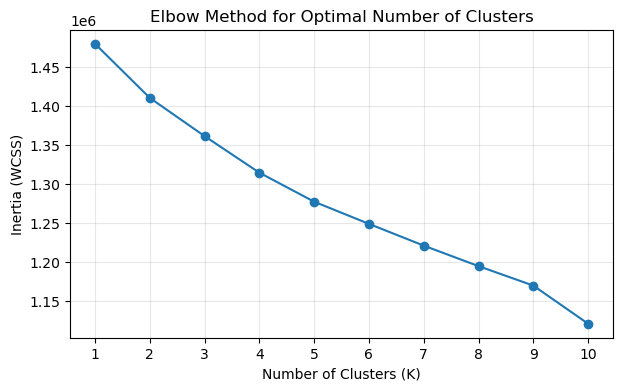

In [38]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Use a reproducible sample to speed up the Elbow Method
from sklearn.model_selection import train_test_split

sample_size = min(50000, len(X_scaled))

X_sample, _ = train_test_split(X_scaled,train_size=sample_size,random_state=42)

# Calculate inertia for different cluster counts
inertia = []
k_values = range(1, 11)

for k in k_values:
    kmeans = KMeans(n_clusters=k,random_state=42,n_init=10)
    kmeans.fit(X_sample)
    inertia.append(kmeans.inertia_)

# Plot the Elbow curve
plt.figure(figsize=(7, 4))
plt.plot(k_values, inertia, marker='o')
plt.title('Elbow Method for Optimal Number of Clusters')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia (WCSS)')
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.show()

### PCA (Principal Component Analysis)

In [39]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Separate features and target
X_pca = df.drop(columns=['Class', 'Transaction_Type'], errors='ignore')
y_pca = df['Class']

# Scale the features
scaler_pca = StandardScaler()
X_scaled_pca = scaler_pca.fit_transform(X_pca)

print("Scaled feature shape:", X_scaled_pca.shape)
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Separate features and target
X_pca = df.drop(columns=['Class', 'Transaction_Type'], errors='ignore')
y_pca = df['Class']

# Scale the features
scaler_pca = StandardScaler()
X_scaled_pca = scaler_pca.fit_transform(X_pca)

print("Scaled feature shape:", X_scaled_pca.shape)

Scaled feature shape: (283726, 30)
Scaled feature shape: (283726, 30)


In [40]:
# Apply PCA to reduce features to 2 dimensions
pca = PCA(n_components=2, random_state=42)
X_pca_2d = pca.fit_transform(X_scaled_pca)

# Display explained variance
print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance explained:",pca.explained_variance_ratio_.sum() * 100,"%")

Explained variance ratio: [0.0655915  0.05634035]
Total variance explained: 12.193184997726018 %


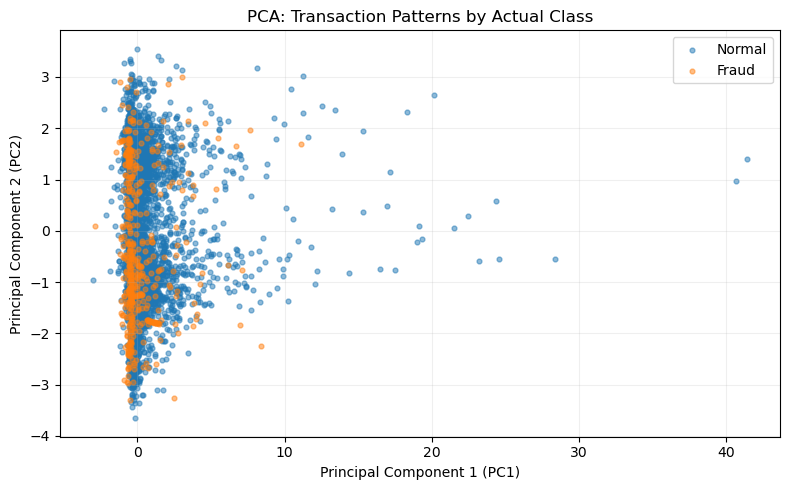

In [42]:
# Prepare data for visualization
pca_df = pd.DataFrame({
    'PC1': X_pca_2d[:, 0],
    'PC2': X_pca_2d[:, 1],
    'Class': y_pca.to_numpy()})

# Sample normal transactions and retain all fraud transactions
normal_sample = pca_df[pca_df['Class'] == 0].sample(
    n=min(10000, (pca_df['Class'] == 0).sum()),random_state=42)

fraud_transactions = pca_df[pca_df['Class'] == 1]

plot_df = pd.concat([normal_sample, fraud_transactions])

# Plot the two principal components
plt.figure(figsize=(8,5))

for class_value, label in [(0, 'Normal'), (1, 'Fraud')]:
    subset = plot_df[plot_df['Class'] == class_value]
    plt.scatter(subset['PC1'],subset['PC2'],label=label,alpha=0.5,s=12)

plt.title('PCA: Transaction Patterns by Actual Class')
plt.xlabel('Principal Component 1 (PC1)')
plt.ylabel('Principal Component 2 (PC2)')
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### Isolation Forest

#### Step 1: Prepare the features

In [43]:
# Prepare features and actual labels
X_if = df.drop(columns=['Class', 'Transaction_Type'],errors='ignore')

y_actual = df['Class']

print("Feature shape:", X_if.shape)
print("Target shape:", y_actual.shape)

Feature shape: (283726, 30)
Target shape: (283726,)


#### Step 2: Train Isolation Forest

In [44]:
from sklearn.ensemble import IsolationForest

# Initialize the Isolation Forest model
iso_forest = IsolationForest(
    n_estimators=100,
    contamination=0.002,
    random_state=42,
    n_jobs=-1
)

# Train the model without using Class
iso_forest.fit(X_if)

# Predict anomalies: -1 = anomaly, 1 = normal
anomaly_predictions = iso_forest.predict(X_if)

# Convert predictions to 1 = anomaly, 0 = normal
y_anomaly = (anomaly_predictions == -1).astype(int)

print("Isolation Forest training completed.")
print("Detected anomalies:", y_anomaly.sum())
print("Total transactions:", len(y_anomaly))

Isolation Forest training completed.
Detected anomalies: 568
Total transactions: 283726


#### Step 3: Compare anomalies with actual fraud labels

In [45]:
# Compare actual Class with detected anomalies
comparison = pd.crosstab(y_actual, y_anomaly, rownames=['Actual Class'], colnames=['Detected Anomaly'], margins=True)
print(comparison)

Detected Anomaly       0    1     All
Actual Class                         
0                 282781  472  283253
1                    377   96     473
All               283158  568  283726


#### Step 4: Evaluate anomaly detection

In [46]:
from sklearn.metrics import (confusion_matrix,precision_score,recall_score,f1_score,classification_report)

# Evaluate anomalies as predictions of fraud
print("Confusion Matrix:")
print(confusion_matrix(y_actual, y_anomaly))
print("\nPrecision:", precision_score(y_actual, y_anomaly, zero_division=0))
print("Fraud Recall:", recall_score(y_actual, y_anomaly, zero_division=0))
print("F1-score:", f1_score(y_actual, y_anomaly, zero_division=0))
print("\nClassification Report:")
print(classification_report(y_actual, y_anomaly,target_names=['Normal', 'Fraud'],zero_division=0))

Confusion Matrix:
[[282781    472]
 [   377     96]]

Precision: 0.16901408450704225
Fraud Recall: 0.2029598308668076
F1-score: 0.1844380403458213

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00    283253
       Fraud       0.17      0.20      0.18       473

    accuracy                           1.00    283726
   macro avg       0.58      0.60      0.59    283726
weighted avg       1.00      1.00      1.00    283726



#### Step 5: Visualize actual fraud versus detected anomalies

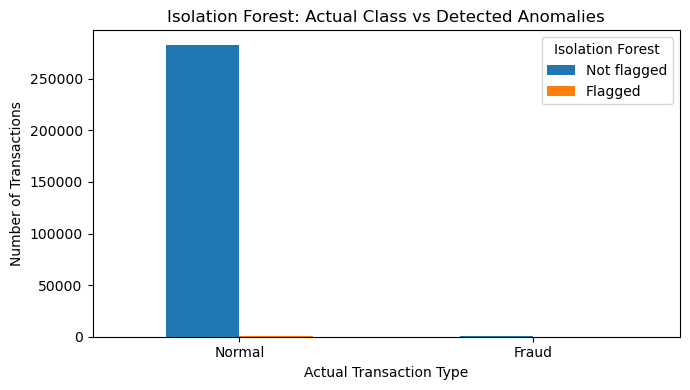

In [48]:
anomaly_counts = pd.DataFrame({'Actual Class': y_actual.to_numpy(),'Detected Anomaly': y_anomaly})

plot_counts = pd.crosstab(anomaly_counts['Actual Class'],anomaly_counts['Detected Anomaly'])

plot_counts.index = ['Normal', 'Fraud']
plot_counts.columns = ['Not flagged', 'Flagged']

plot_counts.plot(kind='bar', figsize=(7, 4))

plt.title('Isolation Forest: Actual Class vs Detected Anomalies')
plt.xlabel('Actual Transaction Type')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=0)
plt.legend(title='Isolation Forest')
plt.tight_layout()
plt.show()

### Conclusion

The project explored Logistic Regression, Decision Tree, and Random Forest for fraud detection. The most appropriate supervised model should be selected based on its actual precision, recall, F1-score, and ROC-AUC results, rather than accuracy alone, because fraudulent transactions are rare. Random Forest can capture complex patterns, while class weighting can help the model pay more attention to fraudulent transactions.

Unsupervised techniques such as K-Means, PCA, and Isolation Forest provided additional insights into transaction similarities and unusual activity without relying on fraud labels during training. However, unusual transactions are not always fraudulent. Overall, the best approach is the one that detects more genuine fraud while keeping false alarms manageable, based on the evaluation results.